# ✈️ PRCP-1025 · Flight Price Prediction

**Problem statement:** Flight ticket prices are hard to guess – the same flight can cost something different tomorrow. This notebook uses machine learning to understand what drives airfares and to predict them, so customers can plan their journey and airlines can see what prices are sustainable.

| Deliverable | Where |
|---|---|
| **Task 1** – Complete data analysis report | Section 1 |
| **Task 2** – Predictive model for flight prices | Section 2 |
| **Model Comparison Report** – performance of multiple models and best model for production | Section 3 |
| **Report on Challenges Faced** – challenges, technique used and reason | Section 4 |

**Dataset columns:** `Airline`, `Date_of_Journey`, `Source`, `Destination`, `Route`, `Dep_Time`, `Arrival_Time`, `Duration`, `Total_Stops`, `Additional_Info` and the target `Price`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
# 1 · Task 1 – Data Analysis Report
### Load the data and check its quality
Load the file, inspect its structure and statistics, then check missing values and duplicates before cleaning.

In [ ]:
df = pd.read_excel('/content/Flight_Fare.xlsx')

In [ ]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [ ]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [ ]:
df.isnull().sum()

,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,1
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,1
Additional_Info,0


In [ ]:
df.duplicated().sum()

np.int64(220)

In [ ]:
# Drop rows containing null values
df.dropna(inplace=True)

# Drop duplicate rows
df.drop_duplicates(inplace=True)

# Confirm cleaning by checking nulls and duplicates again
print("Remaining missing values:")
print(df.isnull().sum())
print("\nRemaining duplicate rows:", df.duplicated().sum())
print("\nNew shape of the dataframe:", df.shape)

Remaining missing values:
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

Remaining duplicate rows: 0

New shape of the dataframe: (10462, 11)


### Feature Engineering: Date and Time Processing
We will extract structured numeric features from `Date_of_Journey`, `Dep_Time`, and `Arrival_Time` so models can understand them.

In [ ]:
# Convert Date_of_Journey to datetime and extract Day and Month
df['Journey_day'] = pd.to_datetime(df['Date_of_Journey'], format='%d/%m/%Y').dt.day
df['Journey_month'] = pd.to_datetime(df['Date_of_Journey'], format='%d/%m/%Y').dt.month

# Extract hours and minutes from Dep_Time
df['Dep_hour'] = pd.to_datetime(df['Dep_Time']).dt.hour
df['Dep_min'] = pd.to_datetime(df['Dep_Time']).dt.minute

# Extract hours and minutes from Arrival_Time
df['Arrival_hour'] = pd.to_datetime(df['Arrival_Time']).dt.hour
df['Arrival_min'] = pd.to_datetime(df['Arrival_Time']).dt.minute

# Drop the original date/time columns now that we have engineered numeric features
df.drop(columns=['Date_of_Journey', 'Dep_Time', 'Arrival_Time'], inplace=True)

# Display the updated dataframe
display(df.head())

/tmp/ipykernel_1766/2171966135.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Dep_hour'] = pd.to_datetime(df['Dep_Time']).dt.hour
/tmp/ipykernel_1766/2171966135.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Dep_min'] = pd.to_datetime(df['Dep_Time']).dt.minute
/tmp/ipykernel_1766/2171966135.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Arrival_hour'] = pd.to_datetime(df['Arrival_Time']).dt.hour
/tmp/ipykernel_1766/2171966135.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To en

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Dep_hour,Dep_min,Arrival_hour,Arrival_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,2h 50m,non-stop,No info,3897,24,3,22,20,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,7h 25m,2 stops,No info,7662,1,5,5,50,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,19h,2 stops,No info,13882,9,6,9,25,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,5h 25m,1 stop,No info,6218,12,5,18,5,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,4h 45m,1 stop,No info,13302,1,3,16,50,21,35


### Exploratory Data Analysis (EDA) & Feature Processing
Let's clean and preprocess remaining non-numeric columns like `Duration` and `Total_Stops` to better understand their relationship with the target variable `Price`.

In [ ]:
# Clean 'Total_Stops' and convert it to numeric values
print("Unique values in Total_Stops:", df['Total_Stops'].unique())
stops_mapping = {'non-stop': 0, '1 stop': 1, '2 stops': 2, '3 stops': 3, '4 stops': 4}
df['Total_Stops'] = df['Total_Stops'].map(stops_mapping)

# Convert 'Duration' into total minutes
def duration_to_minutes(duration):
    hours = 0
    minutes = 0
    parts = duration.split()
    for part in parts:
        if 'h' in part:
            hours = int(part.replace('h', ''))
        elif 'm' in part:
            minutes = int(part.replace('m', ''))
    return hours * 60 + minutes

df['Duration_mins'] = df['Duration'].apply(duration_to_minutes)
df.drop(columns=['Duration'], inplace=True)

display(df.head())

Unique values in Total_Stops: ['non-stop' '2 stops' '1 stop' '3 stops' '4 stops']


,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Dep_hour,Dep_min,Arrival_hour,Arrival_min,Duration_mins
0,IndiGo,Banglore,New Delhi,BLR → DEL,0,No info,3897,24,3,22,20,1,10,170
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2,No info,7662,1,5,5,50,13,15,445
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2,No info,13882,9,6,9,25,4,25,1140
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1,No info,6218,12,5,18,5,23,30,325
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1,No info,13302,1,3,16,50,21,35,285


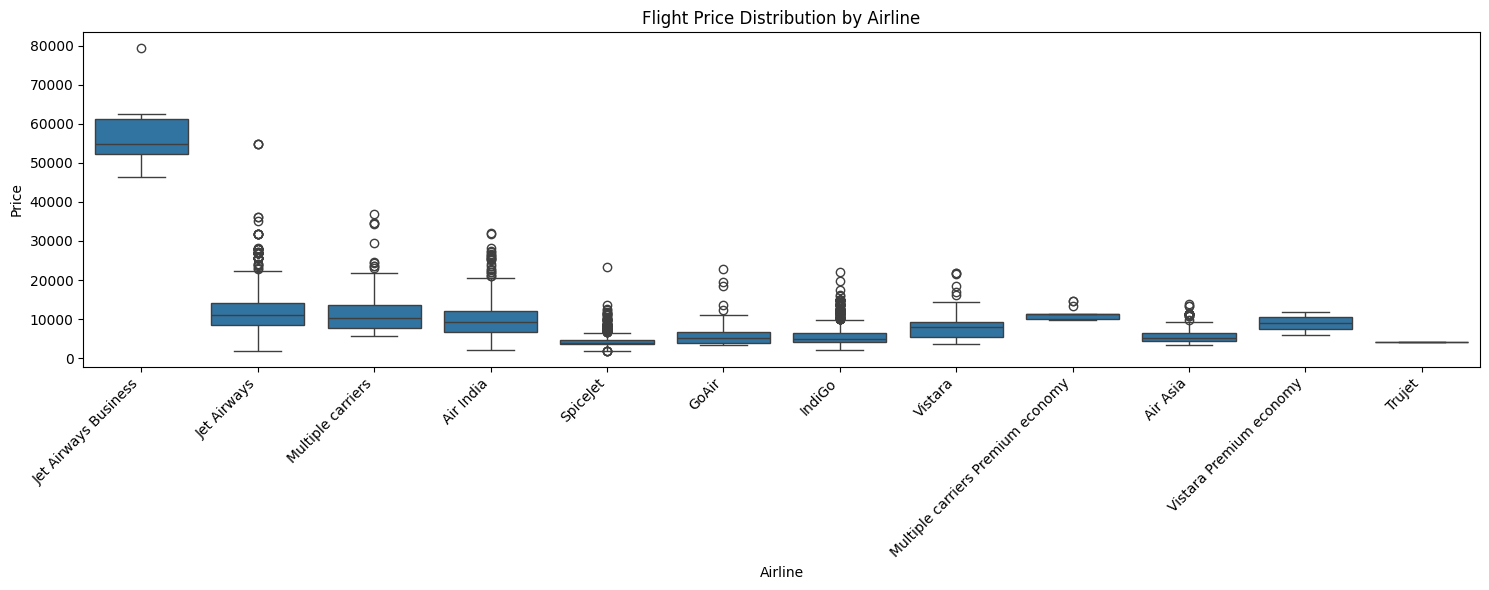

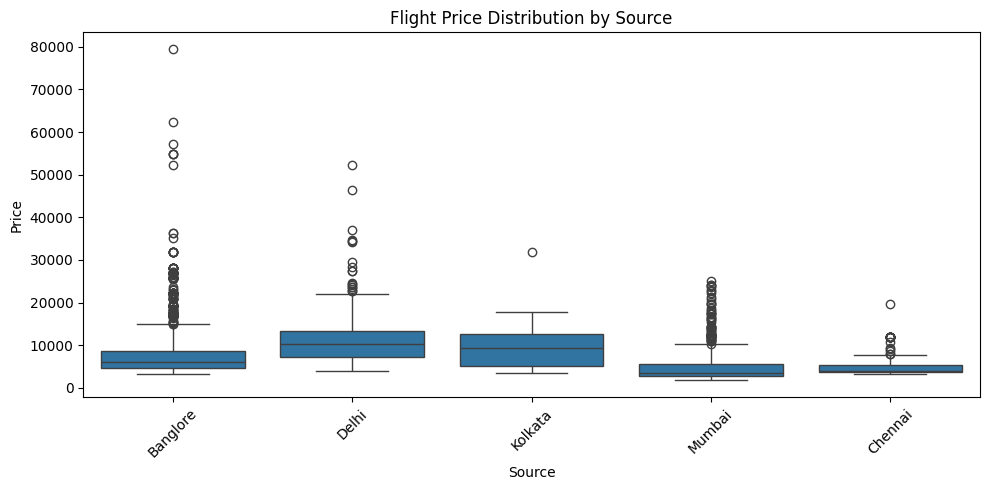

In [ ]:
# Visualize relationships between categorical features and Price
plt.figure(figsize=(15, 6))
sns.boxplot(x='Airline', y='Price', data=df.sort_values('Price', ascending=False))
plt.title('Flight Price Distribution by Airline')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(x='Source', y='Price', data=df.sort_values('Price', ascending=False))
plt.title('Flight Price Distribution by Source')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

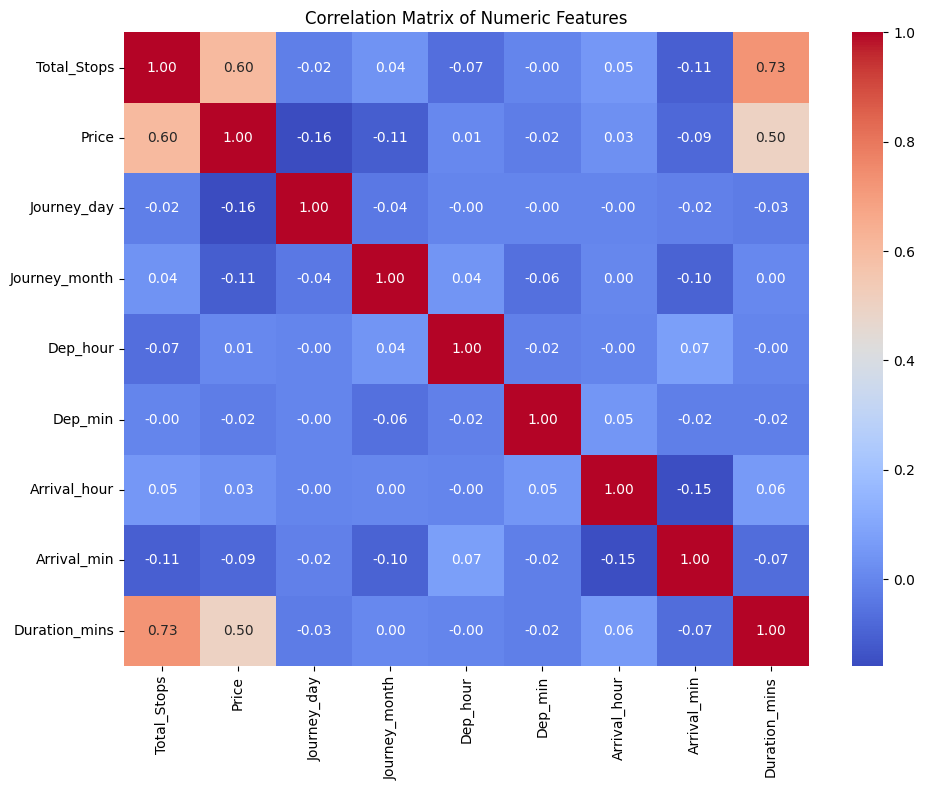

In [ ]:
# Check correlations among numeric features
numeric_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

### Additional EDA – target, stops, month, duration and outliers
The cells above explored airline / source against price and the correlations. The next three cells add the missing pieces of the analysis: the shape of the target variable, price versus stops / month / duration, and a check of the very expensive tickets.

In [ ]:
# Extra EDA 1: distribution of the target variable (Price) and of the main categorical features
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(df['Price'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Price distribution')
sns.histplot(np.log1p(df['Price']), bins=50, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('log(1 + Price) distribution')
sns.countplot(x='Total_Stops', data=df, ax=axes[2])
axes[2].set_title('Number of flights by Total_Stops')
plt.tight_layout()
plt.show()

print('Skewness of Price      :', round(df['Price'].skew(), 2))
print('Skewness of log(Price) :', round(np.log1p(df['Price']).skew(), 2))
print('\nShare of flights by airline:')
print((df['Airline'].value_counts(normalize=True) * 100).round(1).to_string())

In [ ]:
# Extra EDA 2: price vs number of stops, journey month and flight duration
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.boxplot(x='Total_Stops', y='Price', data=df, ax=axes[0])
axes[0].set_title('Price by Total_Stops')
sns.boxplot(x='Journey_month', y='Price', data=df, ax=axes[1])
axes[1].set_title('Price by Journey_month')
sns.scatterplot(x='Duration_mins', y='Price', hue='Total_Stops', data=df, palette='viridis', alpha=0.5, ax=axes[2])
axes[2].set_title('Duration vs Price')
plt.tight_layout()
plt.show()

print('Median price by Total_Stops:')
print(df.groupby('Total_Stops')['Price'].median().to_string())

In [ ]:
# Extra EDA 3: outlier check - who pays the very high prices?
q1, q3 = df['Price'].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
price_outliers = df[df['Price'] > upper_fence]
print(f'IQR upper fence = {upper_fence:,.0f}; tickets above it: {len(price_outliers)} ({len(price_outliers)/len(df):.1%})')
print('\nAirlines among these high-priced tickets:')
print(price_outliers['Airline'].value_counts().to_string())
print('\nMost expensive tickets:')
display(df.nlargest(5, 'Price')[['Airline', 'Source', 'Destination', 'Total_Stops', 'Duration_mins', 'Additional_Info', 'Price']])

**What the additional EDA shows**
* **`Price` is right-skewed** (skewness ≈ 1.86); after a log transform it becomes nearly symmetric (≈ −0.23). Most tickets are cheap or mid-priced, a few are very expensive.
* **Airline mix:** Jet Airways (≈ 35 %), IndiGo (≈ 19 %) and Air India (≈ 16 %) operate most flights; the premium products (*Jet Airways Business*, *Premium economy*) are very rare.
* **Stops:** the median price rises steadily with stops – non-stop ≈ 4,667, 1 stop ≈ 10,262, 2 stops ≈ 12,723, 3 stops ≈ 13,007, 4 stops ≈ 17,686.
* **Duration:** longer flights are generally more expensive, mostly because longer flights have more stops.
* **Outliers:** only 94 tickets (≈ 0.9 %) lie above the IQR fence (≈ 23,026). They are mainly Jet Airways, Air India and Multiple-carrier flights, plus all six *Jet Airways Business* tickets (highest price 79,512). These are real premium fares, not errors, so they are **kept** in the data.

### EDA Summary of Columns:
- **Important Columns**:
  - `Price`: The target variable.
  - `Total_Stops` & `Duration_mins`: Strong positive correlation with flight fares (more stops or longer duration generally lead to higher price).
  - `Airline` & `Destination`/`Source`: Categorical variables showing significant variance in ticket prices (e.g., Jet Airways is generally more expensive).
  - `Journey_day` & `Journey_month`: Important because pricing is highly seasonal and affected by the day of the week or peak seasons.
- **Unimportant/Redundant Columns**:
  - `Route`: Redundant because `Total_Stops` and `Source`/`Destination` capture the same pathway information.
  - `Additional_Info`: Often contains 'No info' (~80% of rows), which might not provide strong predictive signal.

---
# 2 · Task 2 – Predictive Model for Flight Prices
Prepare the data, then train and evaluate several models (Linear Regression, Decision Tree, Random Forest, XGBoost, SVR), tune the best candidates and analyse the final model.

### Data Preparation for Modeling
We will drop the redundant features (`Route`, `Additional_Info`), encode the categorical columns (`Airline`, `Source`, `Destination`) using one-hot encoding, and split our dataset into train and test sets.

In [ ]:
from sklearn.model_selection import train_test_split

# Drop redundant/unimportant columns
features_df = df.drop(columns=['Route', 'Additional_Info'])

# Apply One-Hot Encoding to categorical columns
features_df = pd.get_dummies(features_df, columns=['Airline', 'Source', 'Destination'], drop_first=True)

# Split features and target variable
X = features_df.drop(columns=['Price'])
y = features_df['Price']

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (8369, 28)
Testing set shape: (2093, 28)


### Training and Evaluating Linear Regression Model

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Initialize and train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions on test data
y_pred = lr_model.predict(X_test)

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R-squared (R2) Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

R-squared (R2) Score: 0.5838
Mean Absolute Error (MAE): 1998.64
Root Mean Squared Error (RMSE): 2945.80


### Training and Evaluating Alternative Models (Decision Tree & Random Forest)
We will train a **Decision Tree Regressor** and a **Random Forest Regressor** to compare their R2, MAE, and RMSE scores with our baseline Linear Regression.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Initialize the models
dt_model = DecisionTreeRegressor(random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train Decision Tree
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

# Train Random Forest
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Evaluation helper function
def evaluate_model(name, y_true, y_pred_vals):
    r2_val = r2_score(y_true, y_pred_vals)
    mae_val = mean_absolute_error(y_true, y_pred_vals)
    rmse_val = np.sqrt(mean_squared_error(y_true, y_pred_vals))
    print(f"--- {name} Performance ---")
    print(f"R-squared (R2) Score: {r2_val:.4f}")
    print(f"Mean Absolute Error (MAE): {mae_val:.2f}")
    print(f"Root Mean Squared Error (RMSE): {rmse_val:.2f}\n")
    return r2_val, mae_val, rmse_val

# Print metrics
dt_metrics = evaluate_model("Decision Tree", y_test, dt_pred)
rf_metrics = evaluate_model("Random Forest", y_test, rf_pred)

--- Decision Tree Performance ---
R-squared (R2) Score: 0.7146
Mean Absolute Error (MAE): 1383.09
Root Mean Squared Error (RMSE): 2439.33

--- Random Forest Performance ---
R-squared (R2) Score: 0.8134
Mean Absolute Error (MAE): 1172.66
Root Mean Squared Error (RMSE): 1972.58



/tmp/ipykernel_1766/1224595953.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='R2 Score', data=models_comparison, palette='viridis')


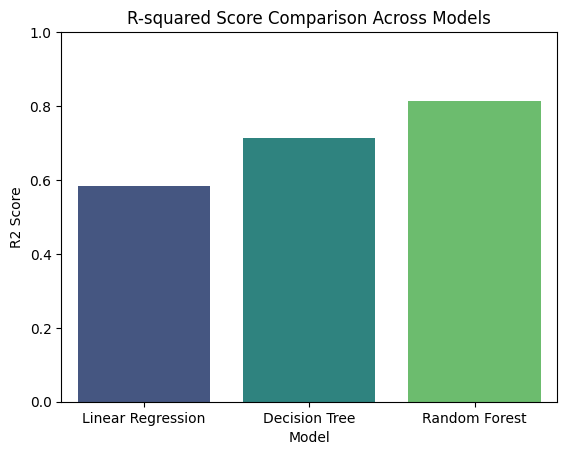

In [ ]:
# Visualize the model comparison
models_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest'],
    'R2 Score': [r2, dt_metrics[0], rf_metrics[0]]
})

sns.barplot(x='Model', y='R2 Score', data=models_comparison, palette='viridis')
plt.title('R-squared Score Comparison Across Models')
plt.ylim(0, 1.0)
plt.show()

### Training an Advanced Gradient Boosting Model (XGBoost)
We train an **XGBoost** regressor to see if we can further boost our prediction performance.

In [ ]:
import xgboost as xgb


# Initialize gradient boosting models
xgb_model = xgb.XGBRegressor(n_estimators=100, random_state=42)


# Train XGBoost
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)



# Evaluate both models
xgb_metrics = evaluate_model("XGBoost", y_test, xgb_pred)


--- XGBoost Performance ---
R-squared (R2) Score: 0.8357
Mean Absolute Error (MAE): 1132.33
Root Mean Squared Error (RMSE): 1850.80



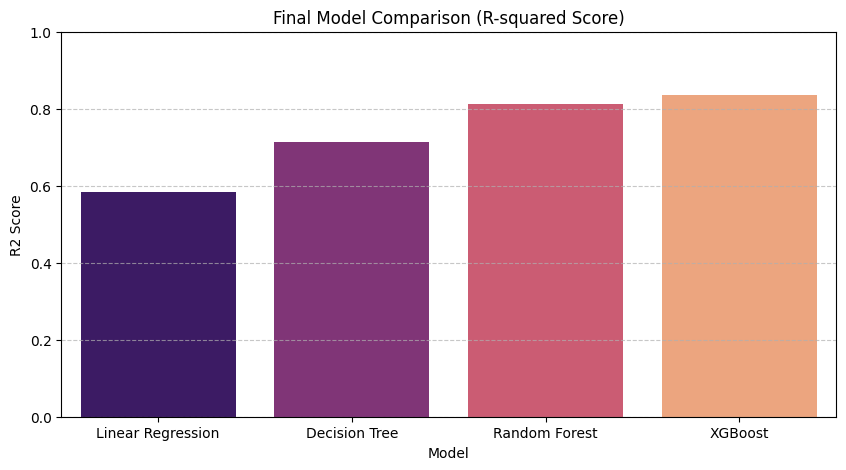

In [ ]:
# Compare all models we have built so far
final_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost'],
    'R2 Score': [r2, dt_metrics[0], rf_metrics[0], xgb_metrics[0]]
})

plt.figure(figsize=(10, 5))
sns.barplot(x='Model', y='R2 Score', data=final_comparison, hue='Model', palette='magma', legend=False)
plt.title('Final Model Comparison (R-squared Score)')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Training and Evaluating Support Vector Regressor (SVR)
Support Vector Regression (SVR) is highly sensitive to feature scales, so we will use `StandardScaler` to scale both features ($X$) and target ($y$) or just features ($X$). Let's scale the features and fit an SVR model with an RBF kernel.

In [ ]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

# SVR performs much better when features are scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train SVR with radial basis function (RBF) kernel
svr_model = SVR(kernel='rbf', C=10000, epsilon=0.1)
svr_model.fit(X_train_scaled, y_train)

# Predict and evaluate
svr_pred = svr_model.predict(X_test_scaled)
svr_metrics = evaluate_model("Support Vector Regressor", y_test, svr_pred)

--- Support Vector Regressor Performance ---
R-squared (R2) Score: 0.7482
Mean Absolute Error (MAE): 1363.85
Root Mean Squared Error (RMSE): 2291.12



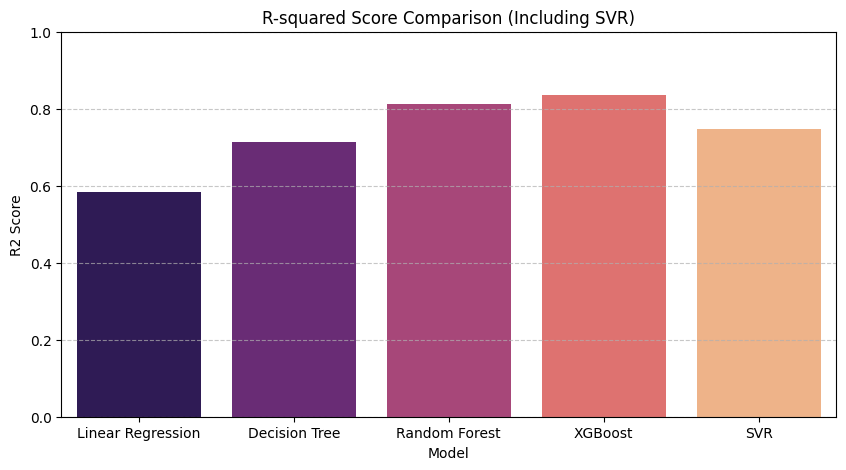

In [ ]:
# Compare all models including SVR
comparison_with_svr = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'SVR'],
    'R2 Score': [r2, dt_metrics[0], rf_metrics[0], xgb_metrics[0], svr_metrics[0]]
})

plt.figure(figsize=(10, 5))
sns.barplot(x='Model', y='R2 Score', data=comparison_with_svr, hue='Model', palette='magma', legend=False)
plt.title('R-squared Score Comparison (Including SVR)')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Hyperparameter Tuning with GridSearchCV
We will define hyperparameter grids for both Random Forest and XGBoost, and search for the best combinations using 3-fold cross-validation.

In [ ]:
from sklearn.model_selection import GridSearchCV

# --- Grid Search for Random Forest ---
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [15, 20],
    'min_samples_split': [2, 5]
}

grid_search_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=rf_param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

print("Starting Grid Search for Random Forest...")
grid_search_rf.fit(X_train, y_train)
best_rf_model = grid_search_rf.best_estimator_
print("Best parameters for Random Forest:", grid_search_rf.best_params_)

# Evaluate Best Random Forest
best_rf_pred = best_rf_model.predict(X_test)
best_rf_metrics = evaluate_model("Tuned Random Forest", y_test, best_rf_pred)

Starting Grid Search for Random Forest...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters for Random Forest: {'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 200}
--- Tuned Random Forest Performance ---
R-squared (R2) Score: 0.8390
Mean Absolute Error (MAE): 1117.24
Root Mean Squared Error (RMSE): 1831.99



In [ ]:
# --- Grid Search for XGBoost ---
xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 7],
    'learning_rate': [0.05, 0.1]
}

grid_search_xgb = GridSearchCV(
    estimator=xgb.XGBRegressor(random_state=42),
    param_grid=xgb_param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

print("Starting Grid Search for XGBoost...")
grid_search_xgb.fit(X_train, y_train)
best_xgb_model = grid_search_xgb.best_estimator_
print("Best parameters for XGBoost:", grid_search_xgb.best_params_)

# Evaluate Best XGBoost
best_xgb_pred = best_xgb_model.predict(X_test)
best_xgb_metrics = evaluate_model("Tuned XGBoost", y_test, best_xgb_pred)

Starting Grid Search for XGBoost...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters for XGBoost: {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 200}
--- Tuned XGBoost Performance ---
R-squared (R2) Score: 0.8419
Mean Absolute Error (MAE): 1183.94
Root Mean Squared Error (RMSE): 1815.44



### Analyzing the Best Model (Tuned XGBoost)
Now that we have selected the Tuned XGBoost model, we will plot the relative importance of each feature to understand what drives flight prices, followed by a scatter plot comparing actual vs. predicted fares.

/tmp/ipykernel_1766/51713271.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(15), palette='viridis')


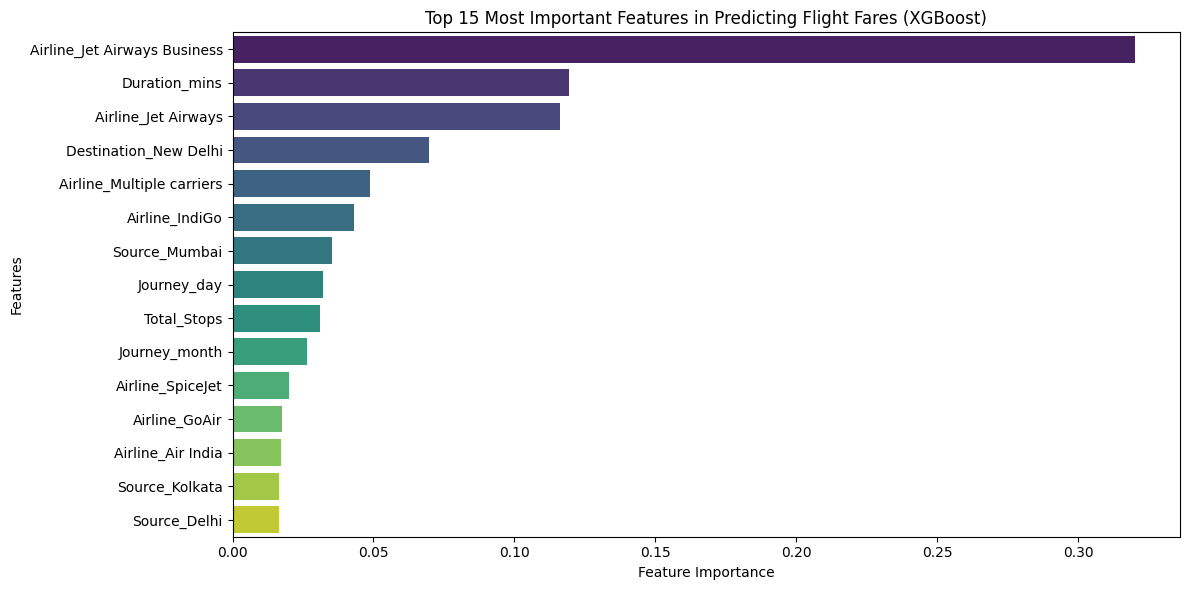

In [ ]:
# Get feature importances from our best XGBoost model
importances = best_xgb_model.feature_importances_
feature_names = X.columns

# Create a DataFrame for visualization
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot top 15 features
plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(15), palette='viridis')
plt.title('Top 15 Most Important Features in Predicting Flight Fares (XGBoost)')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

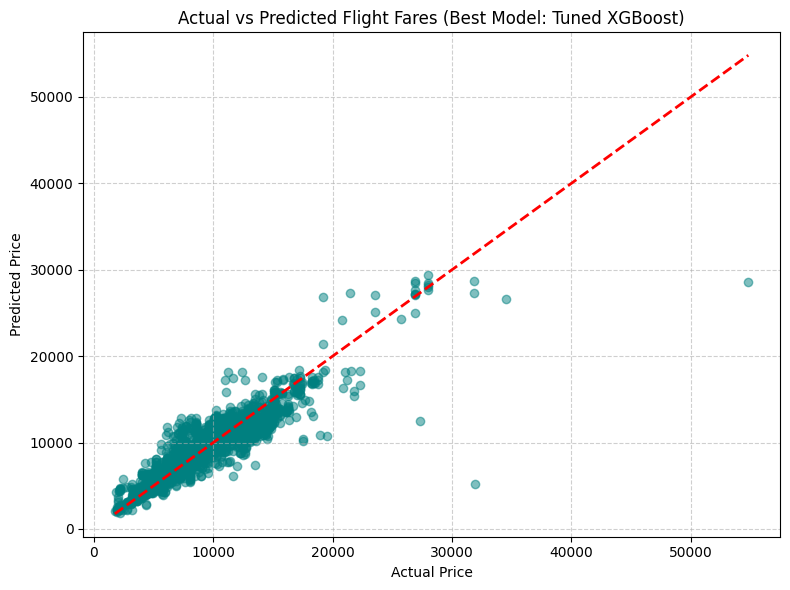

In [ ]:
# Plotting Actual vs Predicted Prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_xgb_pred, alpha=0.5, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Flight Fares (Best Model: Tuned XGBoost)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

---
# 3 · Model Comparison Report
Performance of all models trained above on the same hold-out test set (20 % of the data), collected in one table.

In [ ]:
# Model Comparison Report - collects the metrics already computed in the cells above
comparison_report = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'SVR',
              'Tuned Random Forest', 'Tuned XGBoost'],
    'R2 Score': [r2, dt_metrics[0], rf_metrics[0], xgb_metrics[0], svr_metrics[0], best_rf_metrics[0], best_xgb_metrics[0]],
    'MAE':      [mae, dt_metrics[1], rf_metrics[1], xgb_metrics[1], svr_metrics[1], best_rf_metrics[1], best_xgb_metrics[1]],
    'RMSE':     [rmse, dt_metrics[2], rf_metrics[2], xgb_metrics[2], svr_metrics[2], best_rf_metrics[2], best_xgb_metrics[2]],
}).sort_values('R2 Score', ascending=False).reset_index(drop=True)
display(comparison_report.round(4))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.barplot(x='R2 Score', y='Model', data=comparison_report, hue='Model', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('R2 Score (higher is better)'); axes[0].set_xlim(0, 1)
sns.barplot(x='MAE', y='Model', data=comparison_report.sort_values('MAE'), hue='Model', palette='magma', legend=False, ax=axes[1])
axes[1].set_title('Mean Absolute Error (lower is better)')
plt.tight_layout()
plt.show()

best_r2 = comparison_report.iloc[0]
best_mae = comparison_report.sort_values('MAE').iloc[0]
print(f"Highest R2 : {best_r2['Model']} (R2 = {best_r2['R2 Score']:.4f}, RMSE = {best_r2['RMSE']:.0f})")
print(f"Lowest MAE : {best_mae['Model']} (MAE = {best_mae['MAE']:.0f})")

### Findings and recommendation for production
Results from the run recorded in this notebook (hold-out test set):

| Model | R² | MAE | RMSE |
|---|---|---|---|
| Linear Regression | 0.5838 | 1998.64 | 2945.80 |
| Decision Tree | 0.7146 | 1383.09 | 2439.33 |
| SVR | 0.7482 | 1363.85 | 2291.12 |
| Random Forest | 0.8134 | 1172.66 | 1972.58 |
| XGBoost | 0.8357 | 1132.33 | 1850.80 |
| Tuned Random Forest | 0.8390 | **1117.24** | 1831.99 |
| **Tuned XGBoost** | **0.8419** | 1183.94 | **1815.44** |

* **Linear Regression** is clearly the weakest – flight prices depend on non-linear effects and interactions (airline × stops × route), which a straight line cannot capture.
* **Decision Tree** and **SVR** are better but overfit / under-fit compared with ensembles.
* **Random Forest and XGBoost** are the strongest family; tuning added a further small gain.
* **Recommended model for production: Tuned XGBoost** – it has the highest R² (0.8419) and the lowest RMSE (≈ 1815), which matters because RMSE penalises large errors on expensive tickets most. **Tuned Random Forest** is a very close alternative (R² 0.8390, and slightly lower MAE), so either is a safe choice; the gap between them is small.
* **Expected accuracy:** the model explains about 84 % of the variation in price, with a typical error of roughly 1,100–1,200 per ticket.
* **Next steps for production:** retrain regularly and monitor the error; adding the booking date (days before departure) and holiday/festival information would likely improve accuracy most, as these are not in the dataset.

---
# 4 · Report on Challenges Faced
| # | Challenge faced in the data | Technique used | Reason |
|---|---|---|---|
| 1 | **Missing values** – `Route` and `Total_Stops` empty in one row | `dropna()` | Only one row; a route or stop count cannot be guessed reliably |
| 2 | **220 duplicate rows** | `drop_duplicates()` | Identical records would bias the model and could appear in both train and test sets |
| 3 | **Date and time stored as text** (`24/03/2019`, `22:20`) | `pd.to_datetime` and extraction of day, month, hour, minute; originals dropped | Models need numeric inputs; the date/time parts capture seasonality and time-of-day effects |
| 4 | **`Duration` in free text** (`2h 50m`, `19h`, one row with only minutes) | Custom function → total minutes | Handles hour-only and minute-only values and gives one numeric scale |
| 5 | **`Total_Stops` in words** (`non-stop`, `1 stop` …) | Ordered mapping to 0–4 | Keeps the natural order (more stops = larger number) |
| 6 | **Redundant / low-value columns** (`Route`, `Additional_Info`) | Dropped before modelling | `Route` is explained by source, destination and stops; `Additional_Info` is mostly `No info` |
| 7 | **Categorical features** (`Airline`, `Source`, `Destination`) | One-hot encoding with `drop_first=True` | No natural order between categories; `drop_first` avoids redundant dummy columns |
| 8 | **Skewed price and a few very expensive tickets** | Outliers kept (they are genuine premium fares); tree-based ensembles used | Removing them would hide real cases; tree models handle extreme values well |
| 9 | **Non-linear relationships** – Linear Regression only reached R² ≈ 0.58 | Compared Decision Tree, Random Forest, XGBoost and SVR | Tree ensembles capture interactions between airline, route and stops |
| 10 | **Different feature scales for SVR** | `StandardScaler` (fitted on train, applied to test) | SVR is distance-based and very sensitive to scale; scaling on train only avoids leakage |
| 11 | **Overfitting** – Decision Tree fits training data much better than test data | Random Forest / XGBoost and cross-validated tuning | Averaging many trees reduces variance |
| 12 | **Choosing the best hyper-parameters** | `GridSearchCV` (3-fold CV) for Random Forest and XGBoost | Systematic search that is validated on training folds, not on the test set |
| 13 | **Comparing models fairly** | Same 80/20 split, `random_state=42` and the same metrics (R², MAE, RMSE) for every model | Differences then come from the models themselves and results are reproducible |

---
## Conclusion
Airline, number of stops, duration, route and travel date are the main drivers of flight prices. Tree-based ensemble models predict them far better than a linear model, and the tuned XGBoost model (R² ≈ 0.84) is recommended for production, with tuned Random Forest as a close alternative.